# Tox21 Evaluation: compare models without being fooled

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/CompOmics/ML_AI_Analytical_Chemistry_Course/blob/main/03_Evaluation/notebooks/TD2_tox21_student.ipynb)

**A guided practical for students who do not program | About 60 minutes**

In Foundations, one small tree predicted Active or Inactive from eight
descriptors. Here we compare a small tree, a deep tree and a random forest.
Does better performance on training compounds also mean better performance
on compounds excluded from training?

All three Tox21 practicals use **SR-MMP**, an assay concerning
mitochondrial membrane potential. **Active** means a positive result
in this assay; **Inactive** means a negative result. Neither label is
an overall judgement about human toxicity or safety.

**All code is supplied.** Run the cells from top to bottom with their ▶
buttons. Read each explanation and inspect the output. Leave the code
unchanged. Double-click a **Your answer** text cell to answer in words.

Click **Open in Colab** above. Use the standard CPU runtime; no GPU is
needed. Each notebook runs on its own, so run its loading cells even
if you completed an earlier practical. Internet access is needed.

| Step | Time |
|---|---:|
| Recall the data and sample roles | 15 min |
| Compare a small and a deep tree | 15 min |
| Add a forest and compare scores | 15 min |
| Choose, test and explain mistakes | 15 min |

## 1. Load the same Tox21 data

These preparation steps are identical in all three Tox21 practicals.
First install RDKit, the tool for reading structures and calculating
molecular properties. The version is fixed to keep those calculations
consistent. This cell can take a minute; let it finish before continuing.

In [1]:
%pip -q install rdkit==2025.9.6

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\robbi\.codex\visualizations\2026\10\15\01a13f3a-3ab4-7bb3-9bfa-299d8bf73b96\strawberry-runtime\Scripts\python.exe -m pip install --upgrade pip


Load the tools. `pd` works with tables; `plt` draws plots. The last line
keeps RDKit's routine diagnostic messages brief. We will explicitly count
structures that cannot be read. A name before `=` stores a result.
Read each cell for its purpose; you do not need to memorise Python syntax.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
RDLogger.DisableLog("rdApp.*")

Read the public Tox21 file used by DeepChem. It contains structures and
results for 12 assays. We focus on **SR-MMP** throughout this series.
`smiles` is a text representation of a chemical structure; `mol_id`
identifies a source record. Neither is a measured concentration.

The table shows the first five records. In the assay column, `1` means
Active, `0` means Inactive, and `NaN` means no usable recorded result.

In [3]:
DATA_URL = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/tox21.csv.gz"
raw_data = pd.read_csv(DATA_URL)
print("Source records:", len(raw_data))
raw_data[["mol_id", "smiles", "SR-MMP"]].head()

Source records: 7831


,mol_id,smiles,SR-MMP
0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1,0.0
1,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O,0.0
2,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...,NaN
3,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C,0.0
4,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O,0.0


A missing assay result is not an Inactive result. `dropna` keeps only
records with both a result for SR-MMP and a structure string.
This leaves 5,810 records before the structure-reading check.

In [4]:
data = raw_data.dropna(subset=["SR-MMP", "smiles"]).copy()
print("Records with a result and structure string:", len(data))

Records with a result and structure string: 5810


`map` applies the named structure-reading tool to each string. RDKit
cannot read six structures in this labelled subset. We count them and
leave them out, keeping 5,804 records. `~` means “not”.

In [5]:
data["molecule"] = data["smiles"].map(Chem.MolFromSmiles)
readable = data["molecule"].notna()
print("Structures that could not be read:", (~readable).sum())
data = data.loc[readable].copy()
print("Records kept:", len(data))

Structures that could not be read: 6
Records kept: 5804


### Use eight readable features

Each **feature** is a number calculated from a recorded structure.
These are not measured spectra or experimental toxicity results.
If you also did the strawberry practicals, the eight spectral window
means are replaced here by eight molecular descriptors.

| Feature | Meaning |
|---|---|
| Mass | Calculated molecular weight (g/mol) |
| LogP | Predicted octanol/water partition coefficient, on a log scale |
| H_donors | Number of hydrogen-bond donors |
| H_acceptors | Number of hydrogen-bond acceptors |
| Polar_area | Calculated topological polar surface area (Å²) |
| Rotatable_bonds | Number of rotatable bonds |
| Aromatic_rings | Number of aromatic rings |
| Heavy_atoms | Number of atoms other than hydrogen |

In the next cell, each `map` calculates one descriptor for every molecule.
`head()` shows five rows; `round(2)` rounds only the display.
Row numbers refer to positions in the source file.

In [6]:
features = pd.DataFrame(index=data.index)
features["Mass"] = data["molecule"].map(Descriptors.MolWt)
features["LogP"] = data["molecule"].map(Descriptors.MolLogP)
features["H_donors"] = data["molecule"].map(Descriptors.NumHDonors)
features["H_acceptors"] = data["molecule"].map(Descriptors.NumHAcceptors)
features["Polar_area"] = data["molecule"].map(Descriptors.TPSA)
features["Rotatable_bonds"] = data["molecule"].map(Descriptors.NumRotatableBonds)
features["Aromatic_rings"] = data["molecule"].map(Descriptors.NumAromaticRings)
features["Heavy_atoms"] = data["molecule"].map(Descriptors.HeavyAtomCount)
features.head().round(2)

,Mass,LogP,H_donors,H_acceptors,Polar_area,Rotatable_bonds,Aromatic_rings,Heavy_atoms
0,258.32,1.34,1,5,82.28,3,2,16
1,204.23,1.30,1,2,49.41,2,1,15
3,276.42,3.75,1,2,32.34,7,1,20
4,206.03,-0.99,5,3,135.29,2,0,11
5,290.44,4.82,0,4,36.92,7,0,20


A **reference label** is the assay class recorded in the dataset.
`map` now replaces 0 and 1 with their class names. Inactive is much
more common than Active. We keep these unequal class sizes.

In [7]:
labels = data["SR-MMP"].map({0: "Inactive", 1: "Active"})
print(labels.value_counts())

SR-MMP
Inactive    4886
Active       918
Name: count, dtype: int64


### Stop and explain 1

What are the inputs and target? Why would replacing missing assay results
with Inactive change the question that the model learns to answer?

**Your answer:**

*Write your answer here in words.*

## 2. Give three sample groups different jobs

- **Training:** teach each model.
- **Validation:** compare models and choose one.
- **Test:** check the fixed choice at the end.

**X** means features; **y** means labels. The endings name each group.
`X_development` holds the 4,643 training records from Foundations. We divide
them into 3,482 training and 1,161 validation records. The 1,161 test records
stay the same. The small tree now learns from fewer examples, so its
results can change. Every model uses the same groups.

In [8]:
X_development, X_test, y_development, y_test = train_test_split(
    features, labels, test_size=0.20, random_state=42, stratify=labels
)
X_train, X_validation, y_train, y_validation = train_test_split(
    X_development, y_development, test_size=0.25,
    random_state=42, stratify=y_development
)
print("Training:", len(X_train))
print("Validation:", len(X_validation))
print("Test:", len(X_test))

Training: 3482
Validation: 1161
Test: 1161


The test group was already used in Foundations. We exclude it from choosing
models here, but its reuse is a classroom comparison, not fresh independent
evidence. Related chemical families can still occur across groups.

### Stop and explain 2

Which group teaches the models, which helps choose one, and which checks
the choice? Why should all models use the same training and validation records?

**Your answer:**

*Write your answer here in words.*

## 3. Compare a small and a deep tree

Start with the same two-question depth limit as Foundations. `fit` teaches
the model; for these classifiers, `score` gives accuracy on the named data.
Accuracy is the fraction of predictions matching the reference labels.

As before, `class_weight="balanced"` gives both classes equal total
influence while learning. It does not change the sample counts or how
accuracy is calculated. Use this same setting for every model below.

In [9]:
small_tree = DecisionTreeClassifier(
    max_depth=2, class_weight="balanced", random_state=42
)
small_tree.fit(X_train, y_train)
small_training = small_tree.score(X_train, y_train)
small_validation = small_tree.score(X_validation, y_validation)
print("Small tree, training:", round(small_training, 3))
print("Small tree, validation:", round(small_validation, 3))

Small tree, training: 0.737
Small tree, validation: 0.748


Remove the depth limit so that the tree can keep adding questions. Only
this setting changes; the data and class-balancing rule stay the same.

**Overfitting** means learning details that help on training examples but
do not help as much on other examples. A growing gap between training and
validation accuracy is a warning sign.

In [10]:
deep_tree = DecisionTreeClassifier(class_weight="balanced", random_state=42)
deep_tree.fit(X_train, y_train)
deep_training = deep_tree.score(X_train, y_train)
deep_validation = deep_tree.score(X_validation, y_validation)
print("Deep tree, training:", round(deep_training, 3))
print("Deep tree, validation:", round(deep_validation, 3))

Deep tree, training: 0.997
Deep tree, validation: 0.834


### Stop and explain 3

How much does training accuracy improve for the deeper tree? Does validation
accuracy improve by as much? What does the difference suggest about overfitting?

**Your answer:**

*Write your answer here in words.*

## 4. Add a random forest

A random forest combines predictions from many trees. Here there are 100.
The code repeats the same steps: create, fit, and score on the same groups.
A forest can also fit its training data closely; validation is still needed.

In [11]:
forest = RandomForestClassifier(
    n_estimators=100, class_weight="balanced", random_state=42
)
forest.fit(X_train, y_train)
forest_training = forest.score(X_train, y_train)
forest_validation = forest.score(X_validation, y_validation)
print("Forest, training:", round(forest_training, 3))
print("Forest, validation:", round(forest_validation, 3))

Forest, training: 0.995
Forest, validation: 0.867


Put the scores in one table. Look at validation accuracy because those
compounds did not teach any model. A score of 0.90 means 90% correct.

In [12]:
results = pd.DataFrame({
    "Model": ["Small tree", "Deep tree", "Forest"],
    "Training": [small_training, deep_training, forest_training],
    "Validation": [small_validation, deep_validation, forest_validation]
})
results = results.set_index("Model")
results.round(3)

,Training,Validation
Model,,
Small tree,0.737,0.748
Deep tree,0.997,0.834
Forest,0.995,0.867


The bars show the same scores. Compare with the rule that always predicts
Inactive. It can have high accuracy while missing every Active result.
`==` checks whether labels match Inactive; `mean()` gives the matching fraction.

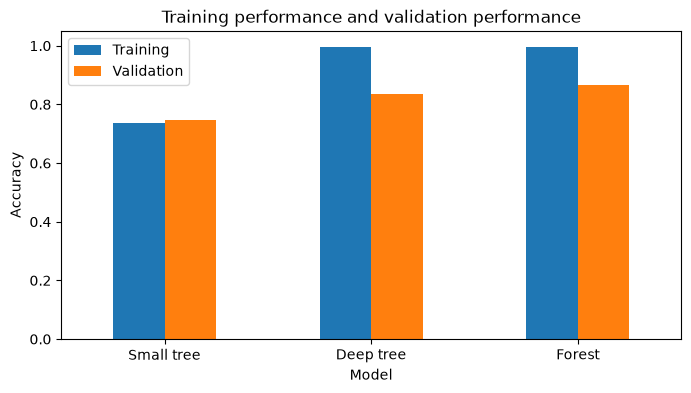

Always Inactive, validation: 0.842


In [13]:
results.plot.bar(figsize=(8, 4), rot=0)
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.title("Training performance and validation performance")
plt.show()
baseline_validation = (y_validation == "Inactive").mean()
print("Always Inactive, validation:", round(baseline_validation, 3))

### Stop and explain 4

Which model has the highest validation accuracy? Does it beat always
predicting Inactive? Why must we still inspect missed Active results?

**Your answer:**

*Write your answer here in words.*

## 5. Choose first, then test

For this teaching comparison, choose the highest validation accuracy.
`idxmax` returns that model's name; the first line links names to trained
models. `models[chosen_name]` retrieves the chosen model. No model is retrained.
A real screening decision would also consider the costs of both error types.

In [14]:
models = {"Small tree": small_tree, "Deep tree": deep_tree, "Forest": forest}
chosen_name = results["Validation"].idxmax()
chosen_model = models[chosen_name]
print("Chosen using validation samples:", chosen_name)

Chosen using validation samples: Forest


Apply the fixed model to test features. Test labels check the predictions;
they did not choose the model. Keep the choice fixed after viewing results.

In the confusion matrix, rows are reference labels and columns predictions.
Active predicted Inactive is a **missed Active result** (false negative);
Inactive predicted Active is a **false alarm** (false positive).

Test accuracy: 0.878


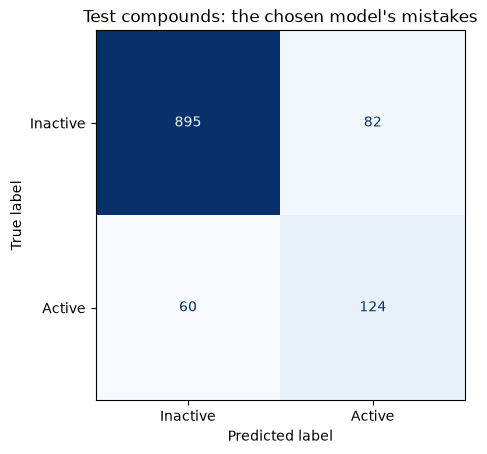

In [15]:
predictions = chosen_model.predict(X_test)
test_accuracy = accuracy_score(y_test, predictions)
print("Test accuracy:", round(test_accuracy, 3))
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, labels=["Inactive", "Active"],
    cmap="Blues", colorbar=False
)
plt.title("Test compounds: the chosen model's mistakes")
plt.show()

### Stop and explain 5

How many Active results were missed and how many false alarms occurred?
Why would trying more settings now make this test less useful as a final check?

**Your answer:**

*Write your answer here in words.*

## 6. Explain the comparison

Training teaches, validation chooses, and testing checks the fixed choice.
A training/validation gap warns about overfitting. Neither high accuracy
nor the Inactive label establishes human safety.

Next, Applications keeps the eight features and test group but asks which
descriptor patterns are unusual, instead of predicting assay classes.

### Stop and explain 6

Write three sentences for the laboratory manager: what the comparison
showed, which model was chosen and one limitation of its results.

**Your answer:**

*Write your answer here in words.*

## Data and reuse

These practicals use the public DeepChem Tox21 CSV, not a new experimental
dataset. Of 7,831 source records, 2,021 have no SR-MMP result and six more
have structures unreadable with the fixed RDKit version. The 5,804 retained
records contain 4,886 Inactive and 918 Active results. Instructors checked
that no identical canonical structure is repeated in this retained subset.
Different structures can still have identical values for these eight descriptors.

These random teaching splits are not DeepChem's default scaffold split:
related chemical families can occur in both training and test groups.
They do not establish performance on unfamiliar chemical families. No
fragments, charges or salts are removed from the recorded structures.

- [Tox21 challenge: assay tasks and original data context](https://tripod.nih.gov/tox21/challenge/about.jsp).
- [DeepChem Tox21 loader and source-file address](https://github.com/deepchem/deepchem/blob/master/deepchem/molnet/load_function/tox21_datasets.py).
- [RDKit molecular descriptor documentation](https://www.rdkit.org/docs/GettingStartedInPython.html#list-of-available-descriptors).

We read DeepChem's public data file directly with pandas and calculate
descriptors with RDKit. Installing the DeepChem Python package is not
required. These exercises do not reproduce the Tox21 challenge benchmark.
An assay prediction or an outlier flag cannot certify human safety.